In [1]:
from dotenv import load_dotenv
load_dotenv()

True

In [ ]:
from langgraph.graph import StateGraph,START, END
from pydantic import BaseModel
from langchain_groq import ChatGroq
from langgraph.types import interrupt, Command
from langgraph.checkpoint.memory import InMemorySaver
from typing import Literal

In [3]:
class MailState(BaseModel):
    question : str = ""
    draft: str = ""
    human_feedback : str = ""
    final : str = ""

In [4]:
llm = ChatGroq(model="openai/gpt-oss-20b")

In [50]:
## creating nodes
## question -> draft -> human feedback -> finalize

def create_draft(state: MailState) -> MailState:
    if state.human_feedback:
        draft = llm.invoke(f""""
                                You generated this mail: {state.draft}
                                Human feedback: {state.human_feedback}
                                rewrie the mail accordingly to the feedback
                            """)
    else: 
        draft = llm.invoke(f"create a mail as per the query: {state.question}")
    state.draft = draft.content 
    return state

def human_fb(state: MailState) -> MailState:
    feedback = interrupt({
        "draft_mail": state.draft,
        "question": "Do you want to continue?"
    })
    fb = (feedback or "").strip().lower()
    if fb in ["yes", "approved", "done"]:
        state.human_feedback = ""
    else:
        state.human_feedback = feedback

    return state

def finalize(state: MailState) -> MailState:
    if state.human_feedback:
        state.final = state.human_feedback
        return state
    state.final = " Mail Sent successfully"
    return state

def route(state: MailState) -> Literal["draft", "finally"]:
    if state.human_feedback:
        return "draft"
    return "finally"

In [51]:
graph = StateGraph(MailState)

graph.add_node("draft", create_draft)
graph.add_node("feedback", human_fb)
graph.add_node("finally", finalize)

graph.add_edge(START, "draft")
graph.add_edge("draft","feedback")
graph.add_conditional_edges("feedback", route)
graph.add_edge("finally", END)

graph= graph.compile(checkpointer=InMemorySaver())

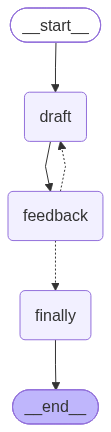

In [52]:
from IPython.display import Image
Image(graph.get_graph().draw_mermaid_png())

In [53]:
config = {"configurable":{"thread_id":"1"}}

In [54]:
response = graph.invoke({
    "question":"Write a mail for a medical leave for 2 days"
}, config=config)

In [55]:
print(response["draft"])

**Subject:** Medical Leave Request – 2 Days (March 27–28, 2026)

Dear [Manager’s Name],

I hope you are doing well. I am writing to formally request medical leave for two days, from **Monday, March 27, 2026** to **Tuesday, March 28, 2026**. A doctor has advised me to rest and recover during this period to ensure a full and timely return to work.

During my absence, I will ensure that all urgent tasks are either completed beforehand or handed over to [Colleague’s Name] with clear instructions. I will remain reachable via email for any critical questions, and I will check my messages periodically.

If a medical certificate or any additional documentation is required, please let me know, and I will provide it promptly.

Thank you for your understanding and support. I look forward to resuming my duties on Wednesday, March 29, 2026.

Best regards,

[Your Full Name]  
[Your Job Title]  
[Department]  
[Phone Number]  
[Email Address]


In [56]:
response = graph.invoke(Command(resume="make the leave for 3 days"), config=config)

In [57]:
print(response["draft"])

                                **Subject:** Medical Leave Request – 3 Days (March 27–29, 2026)

Dear [Manager’s Name],

I hope you are doing well. I am writing to formally request medical leave for **three days**, from **Monday, March 27, 2026** to **Wednesday, March 29, 2026**. A doctor has advised me to rest and recover during this period to ensure a full and timely return to work.

During my absence, I will ensure that all urgent tasks are either completed beforehand or handed over to [Colleague’s Name] with clear instructions. I will remain reachable via email for any critical questions, and I will check my messages periodically.

If a medical certificate or any additional documentation is required, please let me know, and I will provide it promptly.

Thank you for your understanding and support. I look forward to resuming my duties on **Thursday, March 30, 2026**.

Best regards,

[Your Full Name]  
[Your Job Title]  
[Department]  
[Phone Number]  
[Email Address]


In [58]:
response = graph.invoke(Command(resume="approved"), config=config)

In [59]:
response

{'question': 'Write a mail for a medical leave for 2 days',
 'draft': '                                **Subject:** Medical Leave Request – 3 Days (March\u202f27–29,\u202f2026)\n\nDear [Manager’s Name],\n\nI hope you are doing well. I am writing to formally request medical leave for **three days**, from **Monday, March\u202f27,\u202f2026** to **Wednesday, March\u202f29,\u202f2026**. A doctor has advised me to rest and recover during this period to ensure a full and timely return to work.\n\nDuring my absence, I will ensure that all urgent tasks are either completed beforehand or handed over to [Colleague’s Name] with clear instructions. I will remain reachable via email for any critical questions, and I will check my messages periodically.\n\nIf a medical certificate or any additional documentation is required, please let me know, and I will provide it promptly.\n\nThank you for your understanding and support. I look forward to resuming my duties on **Thursday, March\u202f30,\u202f2026